# 03 - Compare models with cross-validation

Notebook 02 trained one model on one 75/25 split and got 86.9%. Two open questions:

1. **Is that score reliable?** Some cell types had only 2-5 test cells, so one lucky or unlucky split can swing their scores a lot.
2. **Would a different model do better?** We'll compare logistic regression against a simple mean-profile baseline and two more complex models: a random forest and a neural network.

Steps: load data -> set up cross-validation -> score five models -> compare per cell type -> look at each model's mix-ups.

In [1]:
# Load the tools I need
import scanpy as sc                    # single-cell data handling (AnnData)
import pandas as pd                    # tables
import matplotlib.pyplot as plt        # plots

# Cross-validation helpers: split the cells into folds, score, and collect predictions
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict

# The five models
from sklearn.dummy import DummyClassifier            # lazy baseline: always guesses the most common type
from sklearn.neighbors import NearestCentroid        # mean-profile baseline: average expression per type
from sklearn.linear_model import LogisticRegression  # simple linear model
from sklearn.ensemble import RandomForestClassifier  # many decision trees that vote
from sklearn.neural_network import MLPClassifier     # small neural network

# Scoring and plotting helpers
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [2]:
# Same dataset as notebooks 01 and 02
adata = sc.datasets.pbmc68k_reduced()
X = adata.X
y = adata.obs["bulk_labels"]

print("X shape (cells, genes):", X.shape)
y.value_counts()

X shape (cells, genes): (700, 765)


bulk_labels
Dendritic                       240
CD14+ Monocyte                  129
CD19+ B                          95
CD4+/CD25 T Reg                  68
CD8+ Cytotoxic T                 54
CD8+/CD45RA+ Naive Cytotoxic     43
CD56+ NK                         31
CD4+/CD45RO+ Memory              19
CD34+                            13
CD4+/CD45RA+/CD25- Naive T        8
Name: count, dtype: int64

## Cross-validation

Instead of one split, cut the cells into **5 equal groups (folds)**. Train on 4, test on the 5th, and repeat 5 times so every cell gets tested exactly once.

- Every cell is used for testing, so rare types get scored on *all* their cells (e.g. all 8 naive CD4 T cells, not just 2).
- We get 5 scores instead of 1, so we can see how much the score wobbles.

`StratifiedKFold` keeps the same mix of cell types in every fold, like `stratify=y` did in notebook 02. 5 folds is the most we can use here, because the rarest type has only 8 cells.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Five Models

- **Baseline**: always guesses the most common type. Anything useful has to beat this.
- **Mean profile**: averages every gene across each cell type to get one "typical cell" per type, then labels a new cell by the typical cell it is closest to. No settings to tune, so it is a strong, honest baseline.
- **Logistic regression**: the same model as notebook 02.
- **Random forest**: hundreds of small decision trees that vote. It can pick up on combinations of genes that logistic regression can't.
- **Neural network**: passes the 765 gene values through one hidden layer of 100 units to an output for each of the 10 cell types, learning its weights over many passes.

Logistic regression and the random forest get `class_weight="balanced"` so rare types aren't ignored. The neural network has no such option, so it is not told to care about rare types.

In [4]:
# Every model in one dictionary: name -> model.
# Same random_state everywhere so results are reproducible.
models = {
    # Floor: anything useful has to beat this
    "Baseline (most common)": DummyClassifier(strategy="most_frequent"),

    # Simple baseline: label each cell by its nearest cell-type average
    "Mean profile": NearestCentroid(),

    # class_weight="balanced" makes mistakes on rare types cost more
    "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced"),

    # 500 trees; n_jobs=-1 uses every CPU core so it runs faster
    "Random forest": RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                            random_state=42, n_jobs=-1),

    # One hidden layer of 100 units. No class_weight option exists for this model.
    "Neural network": MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42),
}

## Score each model

Two scores:

- **accuracy** = fraction of all cells labeled correctly. Dominated by the common types.
- **balanced accuracy** = the average of each cell type's recall. Every type counts equally, so a model that ignores rare types gets punished.

`±` is the standard deviation across the 5 folds, which tells you how much the score wobbles.

In [5]:
rows = []  # one row of results per model

for name, model in models.items():
    # Train and test the model 5 times (once per fold) and score each run
    scores = cross_validate(model, X, y, cv=cv,
                            scoring=["accuracy", "balanced_accuracy", "f1_macro"])

    # Mean across the 5 folds, +/- standard deviation (how much the score wobbles)
    rows.append({
        "model": name,
        "accuracy": f"{scores['test_accuracy'].mean():.1%} ± {scores['test_accuracy'].std():.1%}",
        "balanced accuracy": f"{scores['test_balanced_accuracy'].mean():.1%} ± {scores['test_balanced_accuracy'].std():.1%}",
        "macro-F1": f"{scores['test_f1_macro'].mean():.2f} ± {scores['test_f1_macro'].std():.2f}",
    })

# Turn the list into a table with one row per model
pd.DataFrame(rows).set_index("model")

,accuracy,balanced accuracy,macro-F1
model,,,
Baseline (most common),34.3% ± 0.0%,10.0% ± 0.0%,0.05 ± 0.00
Mean profile,80.4% ± 3.6%,68.8% ± 3.7%,0.69 ± 0.03
Logistic regression,83.7% ± 2.5%,70.0% ± 2.4%,0.70 ± 0.03
Random forest,80.9% ± 2.4%,67.4% ± 2.0%,0.65 ± 0.02
Neural network,79.7% ± 2.7%,65.1% ± 3.7%,0.64 ± 0.04


## Which cell types does each model get right?

`cross_val_predict` gives one prediction per cell, made by the fold where that cell was held out. From these we get recall (of the cells that really are this type, how many did it find?) for every type.

In [6]:
# The four real models (skip the lazy baseline)
real_models = [name for name in models if name != "Baseline (most common)"]

predictions = {}  # one prediction per cell, per model
recall = {}       # recall per cell type, per model

for name in real_models:
    # Each cell is predicted by the fold where it was held out, so no cheating
    predictions[name] = cross_val_predict(models[name], X, y, cv=cv)

    # output_dict=True gives the report as a dictionary we can pull numbers from
    report = classification_report(y, predictions[name], output_dict=True, zero_division=0)
    recall[name] = {cell_type: report[cell_type]["recall"] for cell_type in sorted(y.unique())}

# Table: rows = cell types, columns = models, plus how many cells each type has
recall_table = pd.DataFrame(recall)
recall_table["cells"] = y.value_counts()
recall_table.sort_values("cells", ascending=False).style.format({name: "{:.0%}" for name in real_models})

,Mean profile,Logistic regression,Random forest,Neural network,cells
Dendritic,79%,87%,78%,83%,240
CD14+ Monocyte,95%,91%,95%,92%,129
CD19+ B,95%,97%,100%,98%,95
CD4+/CD25 T Reg,78%,85%,93%,76%,68
CD8+ Cytotoxic T,70%,72%,59%,59%,54
CD8+/CD45RA+ Naive Cytotoxic,70%,67%,51%,60%,43
CD56+ NK,71%,77%,97%,65%,31
CD4+/CD45RO+ Memory,26%,21%,0%,16%,19
CD34+,92%,100%,100%,100%,13
CD4+/CD45RA+/CD25- Naive T,12%,0%,0%,0%,8


## Confusion matrices

Rows = the true cell type, columns = what the model guessed. Now every cell is counted, not just the 175 test cells from notebook 02.

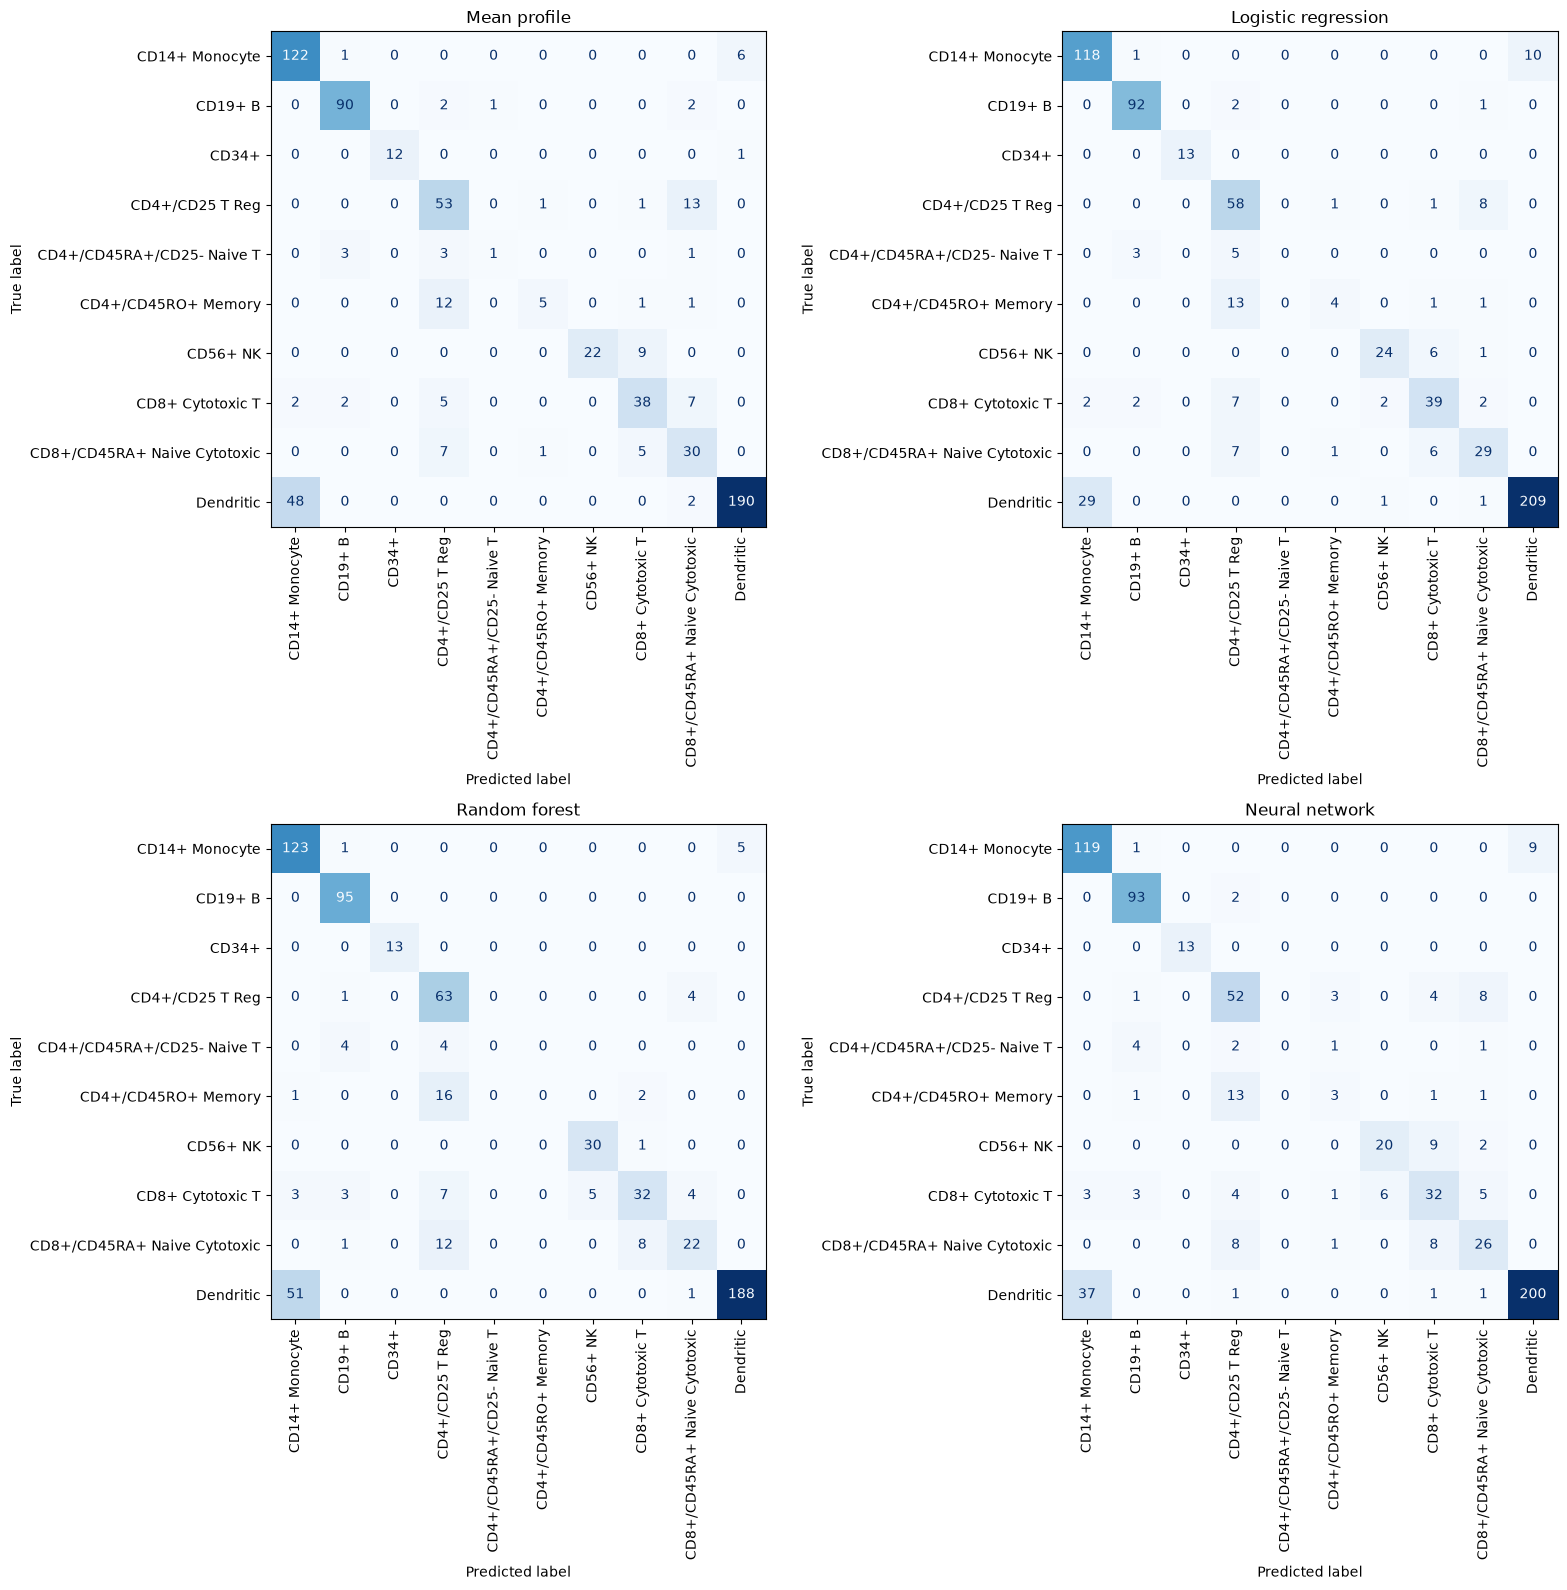

In [7]:
# 2 rows x 2 columns of plots; axes.flat walks through them in order
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

for ax, name in zip(axes.flat, real_models):
    # Rows = true type, columns = predicted type; the diagonal is correct
    ConfusionMatrixDisplay.from_predictions(
        y, predictions[name], xticks_rotation=90, cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)

plt.tight_layout()  # stop the labels from overlapping
plt.show()

## What I learned

**Which model wins overall?** Logistic regression has the best scores: 83.7% accuracy, 70.0% balanced accuracy and 0.70 macro-F1. But its lead over the simple mean-profile baseline (70.0% vs 68.8% balanced accuracy) is smaller than the ± 2.4% wobble across folds, so the two are effectively tied.

**Did complex models help?** No. The random forest (67.4%) and neural network (65.1%) both scored below the simple models. With only 700 cells, the extra flexibility doesn't pay off. The neural network also has no class weighting, which likely hurts it on rare types.

**Which cell types are still hard?** The CD4 T-cell subtypes: CD4+/CD45RO+ Memory (19 cells) and CD4+/CD45RA+/CD25- Naive T (8 cells). Every model finds fewer than 30% of them. B cells, monocytes and CD34+ cells are easy for every model.

**Are T-cell subtypes still being called T Reg?** Yes. The confusion matrices show most memory CD4 T cells are predicted as CD4+/CD25 T Reg. These are closely related cells with similar expression, so the mistake makes biological sense. The other big mix-up is between dendritic cells and CD14+ monocytes, two related myeloid types.

**Next:** check whether these hard types also blend together without labels (clustering and marker genes, notebook 04).